In [3]:
!pip install pingouin


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

In [5]:
df = pd.read_csv("../Data/responses_completo.tsv", sep="\t")


#EDA

In [6]:
variables = [
    "disfrute",
    "competencia",
    "dificultad",
    "ajuste_reto",
    "variedad",
    "rejugar"
]

nombres_variables = {
    "disfrute": "Disfrute",
    "competencia": "Competencia percibida",
    "dificultad": "Dificultad percibida",
    "ajuste_reto": "Ajuste del reto",
    "variedad": "Variedad",
    "rejugar": "Intención de rejugar"
}

condiciones = {
    "H": "Humano",
    "N": "LLM sin telemetría",
    "P": "LLM con telemetría"
}

df["condicion"] = df["level_type"].map(condiciones)

orden = [
    "Humano",
    "LLM sin telemetría",
    "LLM con telemetría"
]

df_promedios = (
    df.groupby(["id", "condicion"], as_index=False)[variables]
      .mean()
)

display(df_promedios.head())

,id,condicion,disfrute,competencia,dificultad,ajuste_reto,variedad,rejugar
0,20261020_130429_S2,Humano,1.0,2.5,-1.5,1.0,1.0,1.0
1,20261020_130429_S2,LLM con telemetría,0.0,0.5,1.5,0.5,2.0,1.0
2,20261020_130429_S2,LLM sin telemetría,-2.5,-2.0,2.5,-2.5,-2.5,-2.5
3,20261020_130434_S5,Humano,0.5,-0.5,-0.5,1.5,0.5,-0.5
4,20261020_130434_S5,LLM con telemetría,0.5,0.0,0.5,2.0,1.5,2.0


In [7]:
estadisticas = (
    df.groupby("condicion")[variables]
      .agg(["mean", "median", "std", "min", "max"])
      .round(3)
)

display(estadisticas)

disfrute                       competencia                \
                       mean median    std min max        mean median    std   
condicion                                                                     
Humano                1.333    1.0  1.239  -3   3       1.542    1.0  1.215   
LLM con telemetría   -0.042    0.5  1.989  -3   3      -0.208   -0.5  2.105   
LLM sin telemetría    0.208    1.0  2.021  -3   3      -0.125    0.5  2.173   

                            ... variedad                       rejugar         \
                   min max  ...     mean median    std min max    mean median   
condicion                   ...                                                 
Humano              -1   3  ...    1.083    1.0  1.381  -3   3   1.292    1.0   
LLM con telemetría  -3   3  ...    0.000    1.0  2.043  -3   3  -0.167    1.0   
LLM sin telemetría  -3   3  ...    0.500    1.5  2.147  -3   3   0.167    1.0   

                                   
                      std min max  
condicion                          
Humano              1.459  -3   3  
LLM con telemetría  2.239  -3   3  
LLM sin telemetría  1.810  -3   3  

[3 rows x 30 columns]

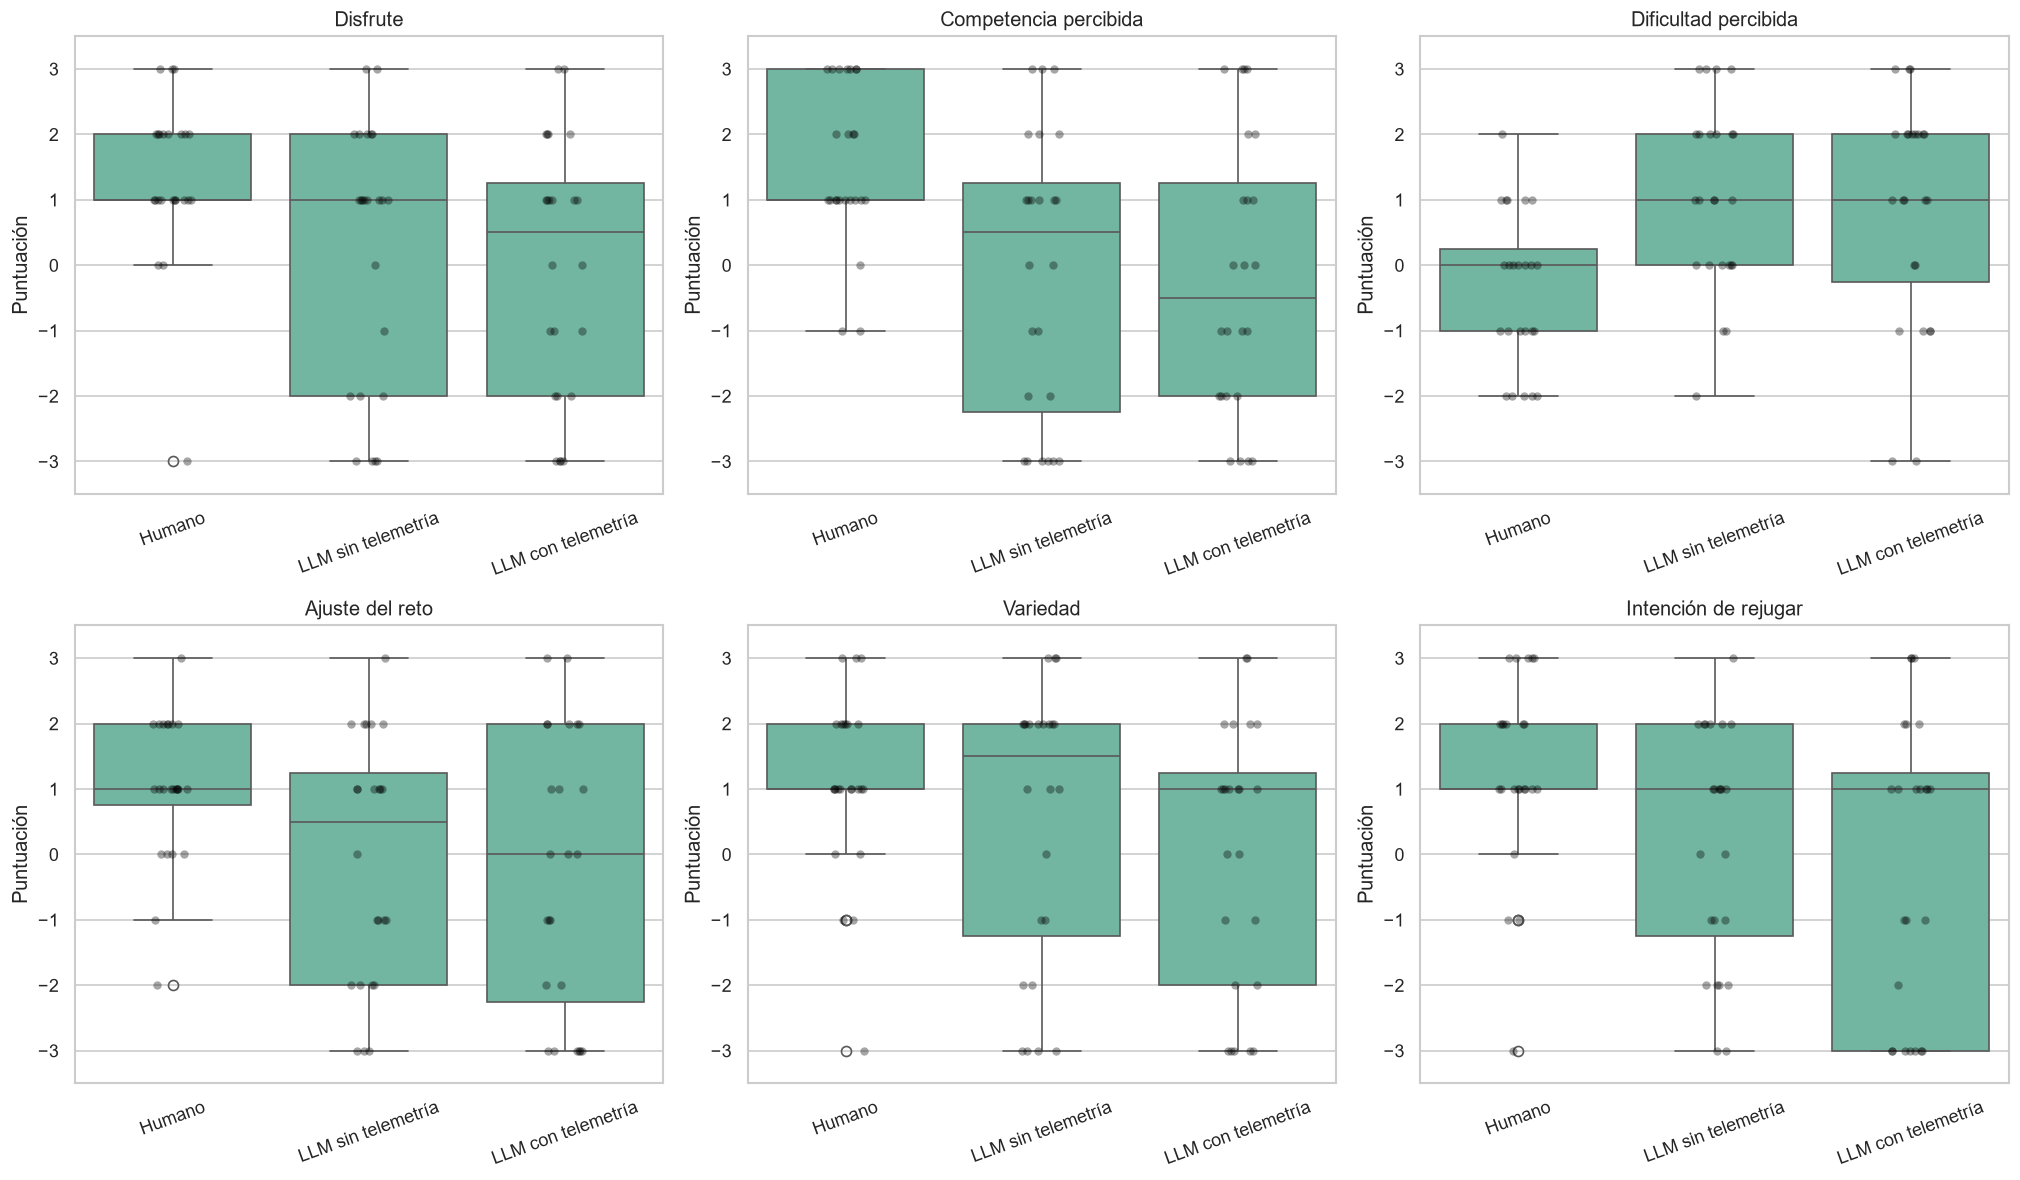

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    sns.boxplot(
        data=df,
        x="condicion",
        y=variable,
        order=orden,
        ax=ax
    )

    sns.stripplot(
        data=df,
        x="condicion",
        y=variable,
        order=orden,
        color="black",
        alpha=0.35,
        jitter=True,
        ax=ax
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Puntuación")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

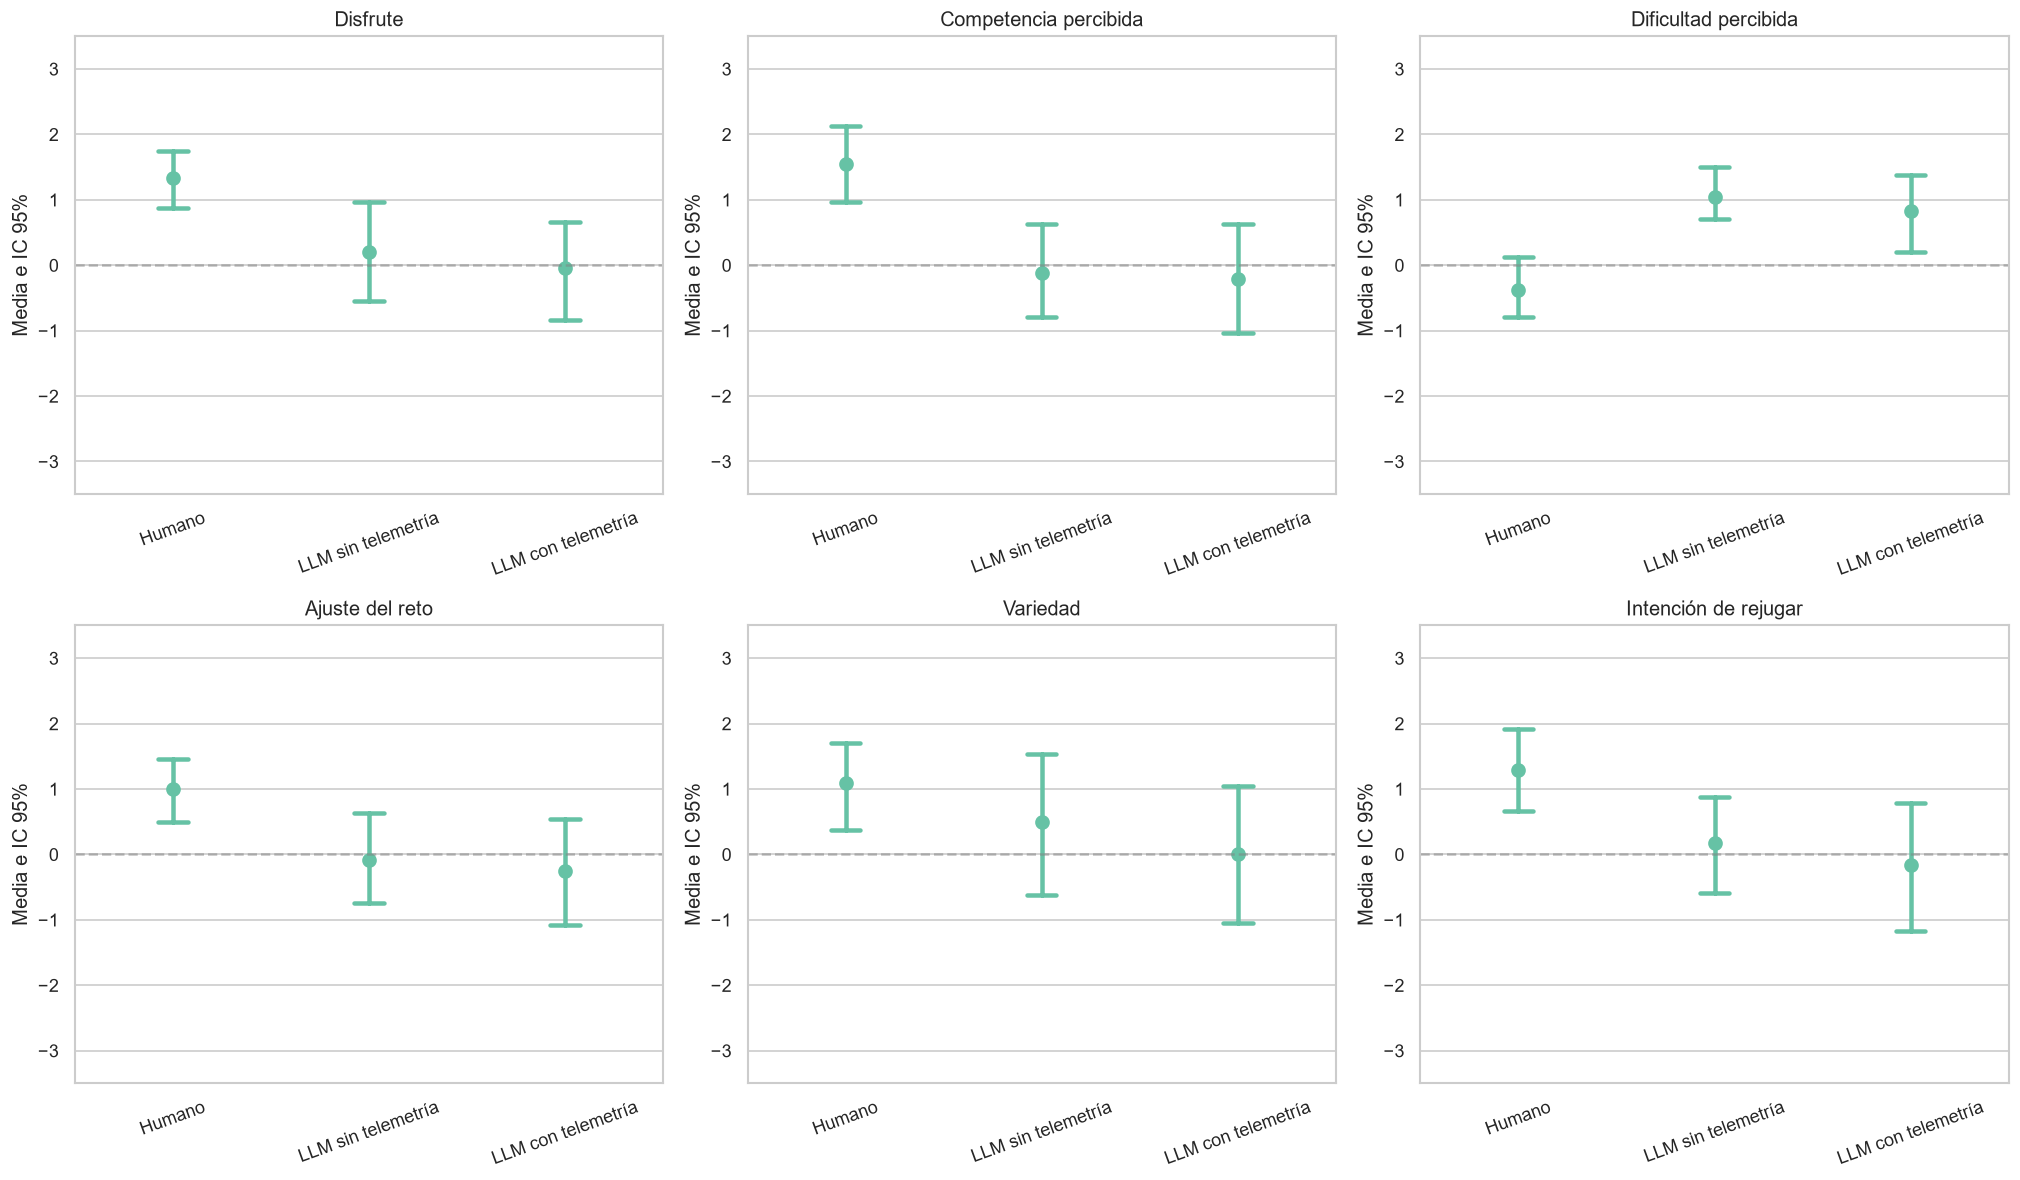

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    sns.pointplot(
        data=df_promedios,
        x="condicion",
        y=variable,
        order=orden,
        errorbar=("ci", 95),
        capsize=0.15,
        markers="o",
        linestyles="none",
        ax=ax
    )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Media e IC 95%")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

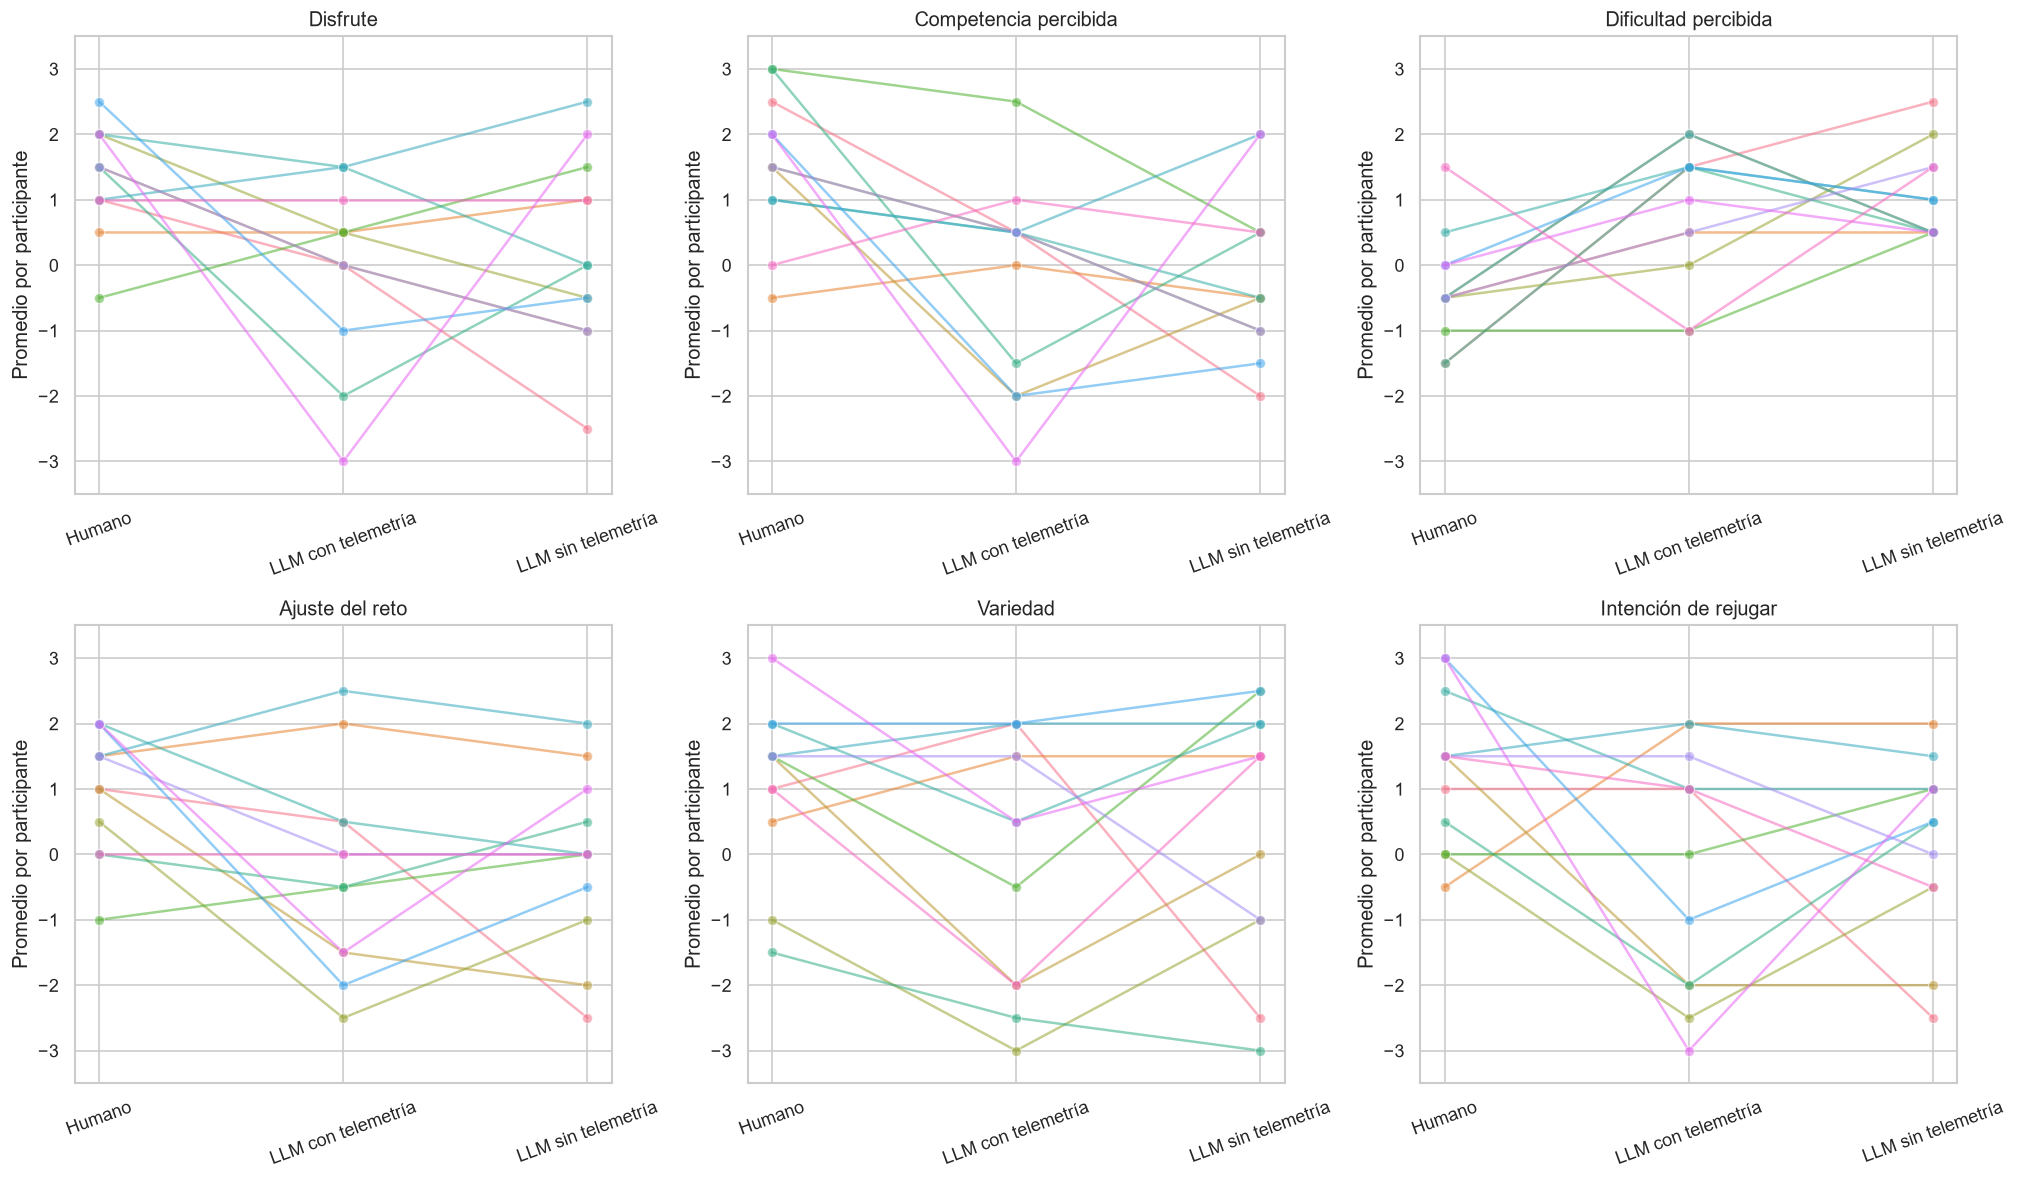

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    sns.lineplot(
        data=df_promedios,
        x="condicion",
        y=variable,
        hue="id",
        units="id",
        estimator=None,
        marker="o",
        alpha=0.55,
        legend=False,
        sort=False,
        ax=ax
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Promedio por participante")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

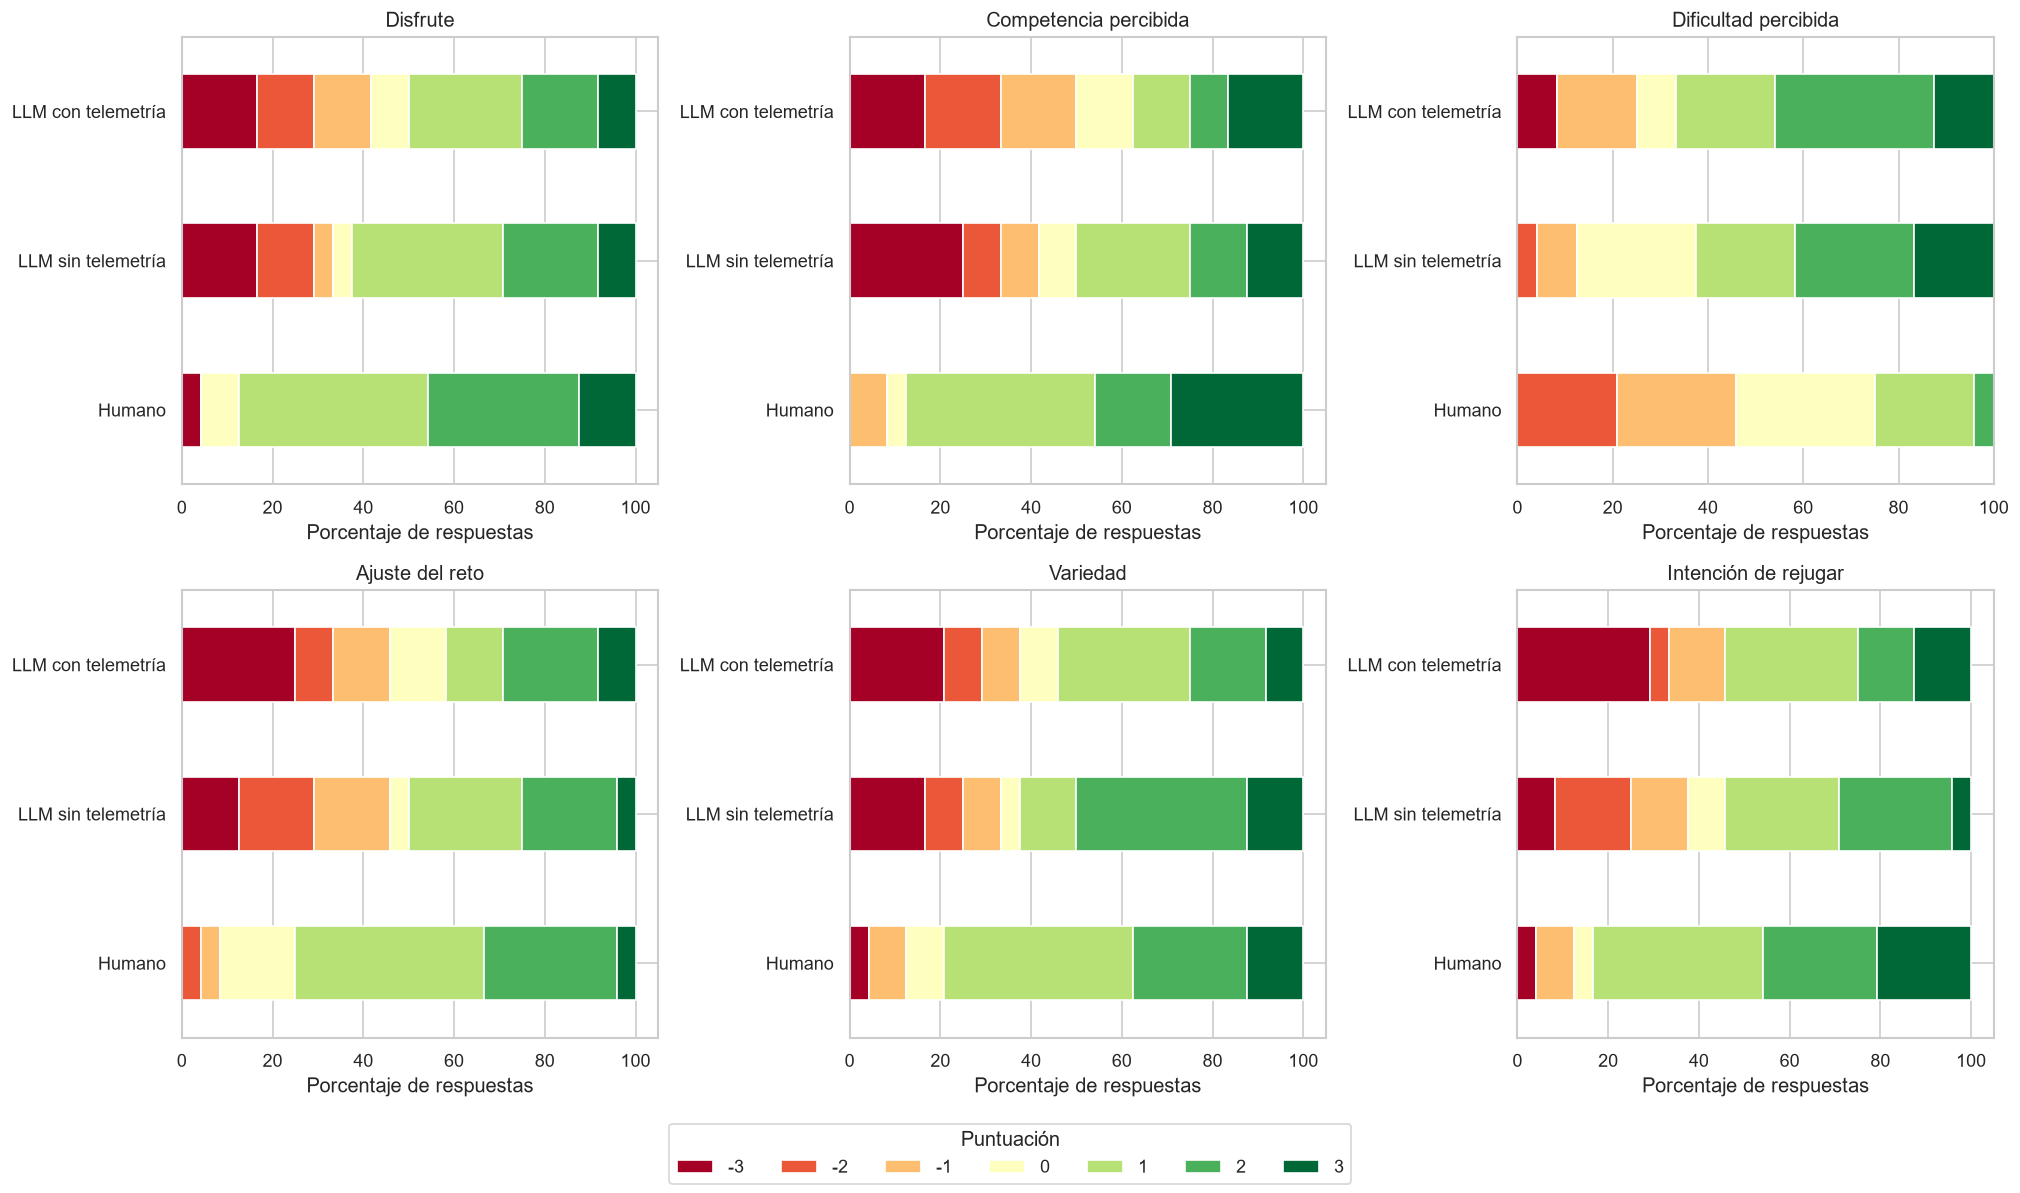

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    tabla = pd.crosstab(
        df["condicion"],
        df[variable],
        normalize="index"
    ) * 100

    tabla = tabla.reindex(
        index=orden,
        columns=range(-3, 4),
        fill_value=0
    )

    tabla.plot(
        kind="barh",
        stacked=True,
        ax=ax,
        colormap="RdYlGn",
        legend=False
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("Porcentaje de respuestas")
    ax.set_ylabel("")

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Puntuación",
    loc="lower center",
    ncol=7
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## Prueba de normalidad (Shapiro-Wilk)

Antes de elegir/afinar el modelo estadístico conviene revisar si, dentro de
cada condición, la distribución de cada variable se aproxima a una normal.
Se usa la prueba de **Shapiro-Wilk** (`pg.normality`), aplicada sobre las
**72 observaciones individuales** (`df`: las 2 repeticiones de cada
condición sin promediar), ya que el modelo de efectos mixtos usará esas
observaciones completas (con `id` como efecto aleatorio) en lugar de
promediarlas por participante. Promediar antes de evaluar normalidad
reduciría artificialmente la varianza y podría cambiar la conclusión de la
prueba (el mismo problema que ya se identificó para el ANOVA promediado).

H0: los datos de ese grupo provienen de una distribución normal.
Un p-valor < 0.05 indica evidencia de que NO son normales.

In [12]:
resultados_normalidad = []

for variable in variables:

    normalidad = pg.normality(
        data=df,
        dv=variable,
        group="condicion"
    ).reset_index().rename(columns={"index": "condicion"})

    normalidad["Variable"] = nombres_variables[variable]

    resultados_normalidad.append(normalidad)

tabla_normalidad = pd.concat(resultados_normalidad, ignore_index=True)

tabla_normalidad["Normal (Shapiro-Wilk)"] = tabla_normalidad["normal"].map(
    {True: "Sí", False: "No"}
)

columnas_normalidad = [
    "Variable",
    "condicion",
    "W",
    "pval",
    "Normal (Shapiro-Wilk)"
]

display(
    tabla_normalidad[columnas_normalidad]
        .rename(columns={"condicion": "Condición", "pval": "p-valor"})
        .round(4)
)

n_no_normales = (tabla_normalidad["normal"] == False).sum()
print(f"\nGrupos (variable x condición) que no pasan Shapiro-Wilk (p < 0.05): {n_no_normales} de {len(tabla_normalidad)}")

,Variable,Condición,W,p-valor,Normal (Shapiro-Wilk)
0,Disfrute,LLM sin telemetría,0.8641,0.0040,No
1,Disfrute,LLM con telemetría,0.9130,0.0411,No
2,Disfrute,Humano,0.8016,0.0003,No
3,Competencia percibida,LLM sin telemetría,0.8841,0.0100,No
4,Competencia percibida,LLM con telemetría,0.9092,0.0339,No
5,Competencia percibida,Humano,0.8620,0.0037,No
6,Dificultad percibida,LLM sin telemetría,0.9315,0.1050,Sí
7,Dificultad percibida,LLM con telemetría,0.8848,0.0104,No
8,Dificultad percibida,Humano,0.9111,0.0373,No
9,Ajuste del reto,LLM sin telemetría,0.9075,0.0312,No



Grupos (variable x condición) que no pasan Shapiro-Wilk (p < 0.05): 17 de 18


## Modelo Lineal de Efectos Mixtos (LMM)

### Etapa 1: Preparación de datos

El LMM se ajusta sobre `df`, es decir, las **72 observaciones individuales**
(12 participantes × 3 condiciones × 2 repeticiones), **sin promediar** por
participante y condición. A diferencia del ANOVA de medidas repetidas, el
LMM puede usar todas las observaciones directamente porque modela la
correlación entre observaciones del mismo participante a través de un
**efecto aleatorio por `id`**, en lugar de requerir una sola fila por
sujeto/condición.

Antes de ajustar cualquier modelo, dejamos preparado lo siguiente:

1. **Nivel de referencia**: fijamos `"Humano"` como condición base de
   `condicion` (equivalente a `level_type == "H"`), ya que es el control
   natural del experimento. Así, los coeficientes del modelo se interpretan
   directamente como la diferencia de cada condición LLM respecto a jugar
   contra un nivel diseñado por una persona.
2. **Valores faltantes**: verificamos que no haya nulos en `id`, `condicion`
   ni en las 6 variables de respuesta.
3. **Balance de observaciones**: confirmamos cuántas filas hay por cada
   combinación de `id` x `condicion` (se espera 2, una por repetición). El
   LMM no requiere este balance perfecto para funcionar, pero es una buena
   verificación de que los datos están completos antes de modelar.

In [13]:
import statsmodels.formula.api as smf

df["condicion"] = pd.Categorical(
    df["condicion"],
    categories=["Humano", "LLM sin telemetría", "LLM con telemetría"],
    ordered=False
)

print("Categorías de 'condicion' (la primera es la referencia):")
print(df["condicion"].cat.categories.tolist())

columnas_clave = ["id", "condicion"] + variables
nulos = df[columnas_clave].isna().sum()

print("\nValores faltantes por columna:")
display(nulos.to_frame("nulos"))

conteo_obs = (
    df.groupby(["id", "condicion"], observed=True)
      .size()
      .reset_index(name="n_observaciones")
)

print("\nResumen de observaciones por participante x condición:")
display(conteo_obs["n_observaciones"].value_counts().to_frame("n_combinaciones id x condicion"))

combinaciones_incompletas = conteo_obs[conteo_obs["n_observaciones"] != 2]
if len(combinaciones_incompletas) == 0:
    print("\nTodas las combinaciones id x condición tienen exactamente 2 observaciones (sin datos faltantes).")
else:
    print("\nCombinaciones con un número de observaciones distinto de 2:")
    display(combinaciones_incompletas)

Categorías de 'condicion' (la primera es la referencia):
['Humano', 'LLM sin telemetría', 'LLM con telemetría']

Valores faltantes por columna:


,nulos
id,0
condicion,0
disfrute,0
competencia,0
dificultad,0
ajuste_reto,0
variedad,0
rejugar,0



Resumen de observaciones por participante x condición:


,n_combinaciones id x condicion
n_observaciones,
2,36



Todas las combinaciones id x condición tienen exactamente 2 observaciones (sin datos faltantes).


### Etapa 2: Primer modelo piloto (Disfrute)

Antes de ajustar los 6 modelos (uno por variable), probamos el procedimiento
con una sola variable, **Disfrute**, para revisar con calma el resultado.

- **Efecto fijo**: `disfrute ~ condicion`. Como `condicion` tiene a
  `"Humano"` como primera categoría (referencia), el modelo estima dos
  coeficientes: la diferencia de `"LLM sin telemetría"` respecto a Humano, y
  la diferencia de `"LLM con telemetría"` respecto a Humano.
- **Efecto aleatorio**: `groups=df["id"]` agrega un intercepto aleatorio por
  participante, para capturar que cada persona tiene su propio nivel base de
  respuesta, independiente de la condición.
- Revisamos la **convergencia** del modelo (el optimizador numérico puede no
  converger, especialmente con muestras pequeñas), el resumen completo de
  coeficientes y la varianza del efecto aleatorio.

In [14]:
modelo_disfrute = smf.mixedlm(
    "disfrute ~ condicion",
    data=df,
    groups=df["id"]
)

resultado_disfrute = modelo_disfrute.fit()

print(f"¿Convergió el modelo?: {resultado_disfrute.converged}\n")

print(resultado_disfrute.summary())

¿Convergió el modelo?: True

                  Mixed Linear Model Regression Results
Model:                   MixedLM       Dependent Variable:       disfrute 
No. Observations:        72            Method:                   REML     
No. Groups:              12            Scale:                    3.1920   
Min. group size:         6             Log-Likelihood:           -142.7165
Max. group size:         6             Converged:                Yes      
Mean group size:         6.0                                              
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                        1.333    0.365  3.656 0.000  0.619  2.048
condicion[T.LLM sin telemetría] -1.125    0.516 -2.181 0.029 -2.136 -0.114
condicion[T.LLM con telemetría] -1.375    0.516 -2.666 0.008 -2.386 -0.364
Group Var      

c:\Users\emago\OneDrive\Documentos\GitHub\Mario-Ai\.venv\Lib\site-packages\statsmodels\base\model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
c:\Users\emago\OneDrive\Documentos\GitHub\Mario-Ai\.venv\Lib\site-packages\statsmodels\base\model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
c:\Users\emago\OneDrive\Documentos\GitHub\Mario-Ai\.venv\Lib\site-packages\statsmodels\base\model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
C:\Users\emago\AppData\Local\Temp\ipykernel_18240\835371592.py:7: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  resultado_disfrute = modelo_disfrute.fit()


### Etapa 3: Modelo para las 6 variables

Repetimos el mismo procedimiento del modelo piloto (`dv ~ condicion`, con
intercepto aleatorio por `id`) para las 6 variables de respuesta.

Para cada modelo registramos:

- Si **convergió** (`resultado.converged`).
- La **varianza del efecto aleatorio** (`Group Var`). Como vimos en el
  modelo piloto de Disfrute, es esperable que en varias variables esta
  varianza salga muy cercana a 0 (con el aviso `SingularMatrixWarning`),
  porque ya comprobamos con un ANOVA de un factor que la mayoría de estas
  variables no muestran diferencias sistemáticas entre participantes
  (los participantes no se parecen más a sí mismos entre condiciones de lo
  que se parecen entre sí). Esto no es un error del ajuste: es información
  real sobre la estructura de los datos y se reporta como tal.
- Los **coeficientes de los dos contrastes** (`LLM sin telemetría` y
  `LLM con telemetría`, ambos respecto a `Humano`) con su p-valor.

Los resultados completos de cada modelo quedan guardados en el diccionario
`modelos_lmm` para poder revisarlos a detalle (y hacer el diagnóstico de
residuos) en la siguiente etapa, sin tener que volver a ajustarlos.

In [15]:
import warnings

modelos_lmm = {}
resumen_modelos = []

for variable in variables:

    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always")

        modelo = smf.mixedlm(
            f"{variable} ~ condicion",
            data=df,
            groups=df["id"]
        )
        resultado = modelo.fit()

    avisos = sorted({w.category.__name__ for w in capturados})

    modelos_lmm[variable] = resultado

    group_var = resultado.cov_re.iloc[0, 0]

    fila = {
        "Variable": nombres_variables[variable],
        "Convergió": resultado.converged,
        "Group Var": round(group_var, 4),
        "Avisos": ", ".join(avisos) if avisos else "Ninguno",
        "Coef. LLM sin telemetría": round(resultado.params.get("condicion[T.LLM sin telemetría]", float("nan")), 3),
        "p LLM sin telemetría": round(resultado.pvalues.get("condicion[T.LLM sin telemetría]", float("nan")), 4),
        "Coef. LLM con telemetría": round(resultado.params.get("condicion[T.LLM con telemetría]", float("nan")), 3),
        "p LLM con telemetría": round(resultado.pvalues.get("condicion[T.LLM con telemetría]", float("nan")), 4),
    }

    resumen_modelos.append(fila)

tabla_resumen_lmm = pd.DataFrame(resumen_modelos)

display(tabla_resumen_lmm)

,Variable,Convergió,Group Var,Avisos,Coef. LLM sin telemetría,p LLM sin telemetría,Coef. LLM con telemetría,p LLM con telemetría
0,Disfrute,True,0.0000,"ConvergenceWarning, SingularMatrixWarning",-1.125,0.0292,-1.375,0.0077
1,Competencia percibida,True,0.0000,"ConvergenceWarning, SingularMatrixWarning",-1.667,0.0022,-1.750,0.0013
2,Dificultad percibida,True,0.0000,ConvergenceWarning,1.417,0.0007,1.208,0.0040
3,Ajuste del reto,True,0.4075,Ninguno,-1.083,0.0228,-1.250,0.0086
4,Variedad,True,1.5878,Ninguno,-0.583,0.1575,-1.083,0.0087
5,Intención de rejugar,True,0.2154,Ninguno,-1.125,0.0311,-1.458,0.0052


### Etapa 4: Diagnóstico de residuos

El supuesto de normalidad de un LMM aplica a los **residuos del modelo**
(lo que el modelo no logra explicar), no a los datos crudos por grupo como
se evaluó en el EDA. Revisamos dos cosas para cada uno de los 6 modelos
guardados en `modelos_lmm`:

1. **Normalidad de los residuos** (`resultado.resid`), con Shapiro-Wilk y
   un QQ-plot. Un QQ-plot muestra los residuos ordenados contra los valores
   que se esperarían si vinieran de una normal perfecta: si los puntos
   siguen la línea diagonal, el supuesto se cumple razonablemente.
2. **Homocedasticidad** (varianza constante de los residuos), con un
   gráfico de residuos vs. valores ajustados (`fittedvalues`). Si los
   puntos se ven dispersos sin un patrón (ni embudo, ni curva), el supuesto
   se cumple razonablemente.

Como la variable de respuesta es una escala Likert discreta (-3 a 3), es
esperable que los residuos no sean perfectamente normales (igual que ya
vimos con los datos crudos); el objetivo aquí es detectar violaciones
graves, no exigir una normalidad perfecta.

In [16]:
resultados_normalidad_residuos = []

for variable in variables:

    residuos = modelos_lmm[variable].resid

    normalidad_resid = pg.normality(residuos)

    resultados_normalidad_residuos.append({
        "Variable": nombres_variables[variable],
        "W": normalidad_resid["W"].iloc[0],
        "p-valor": normalidad_resid["pval"].iloc[0],
        "Normal (Shapiro-Wilk)": "Sí" if normalidad_resid["normal"].iloc[0] else "No"
    })

tabla_normalidad_residuos = pd.DataFrame(resultados_normalidad_residuos).round(4)

display(tabla_normalidad_residuos)

,Variable,W,p-valor,Normal (Shapiro-Wilk)
0,Disfrute,0.9479,0.0048,No
1,Competencia percibida,0.9444,0.0032,No
2,Dificultad percibida,0.9577,0.0165,No
3,Ajuste del reto,0.9646,0.0404,No
4,Variedad,0.9909,0.8878,Sí
5,Intención de rejugar,0.9622,0.0295,No


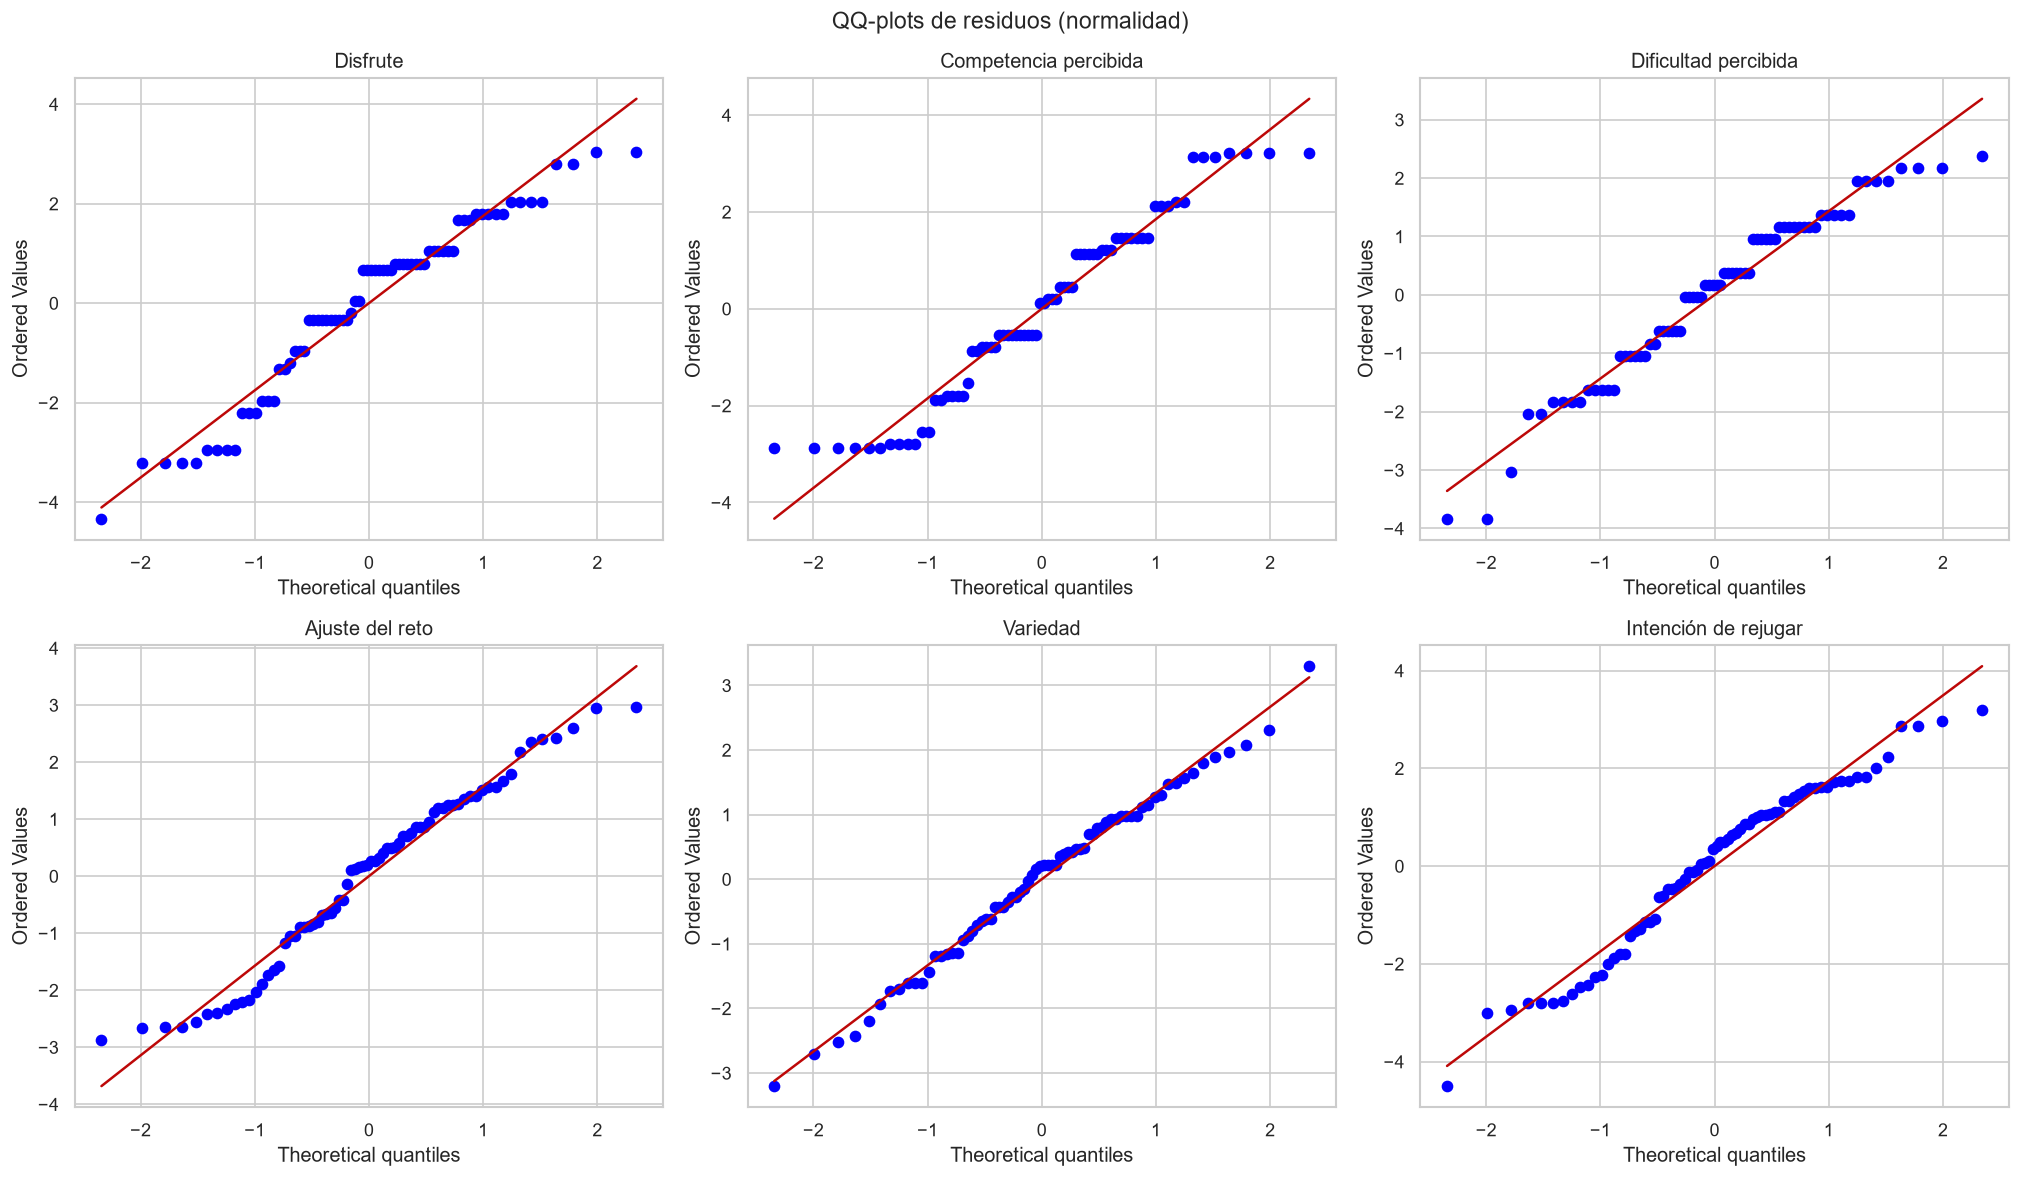

In [17]:
import scipy.stats as stats
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    residuos = modelos_lmm[variable].resid
    stats.probplot(residuos, dist="norm", plot=ax)
    ax.set_title(nombres_variables[variable])
    
    # Recolorear puntos y línea
    ax.lines[0].set_markerfacecolor("#0300ff")
    ax.lines[0].set_markeredgecolor("#0300ff")
    ax.lines[1].set_color("#bd0808")

fig.suptitle("QQ-plots de residuos (normalidad)", fontsize=14)
fig.tight_layout()
plt.show()

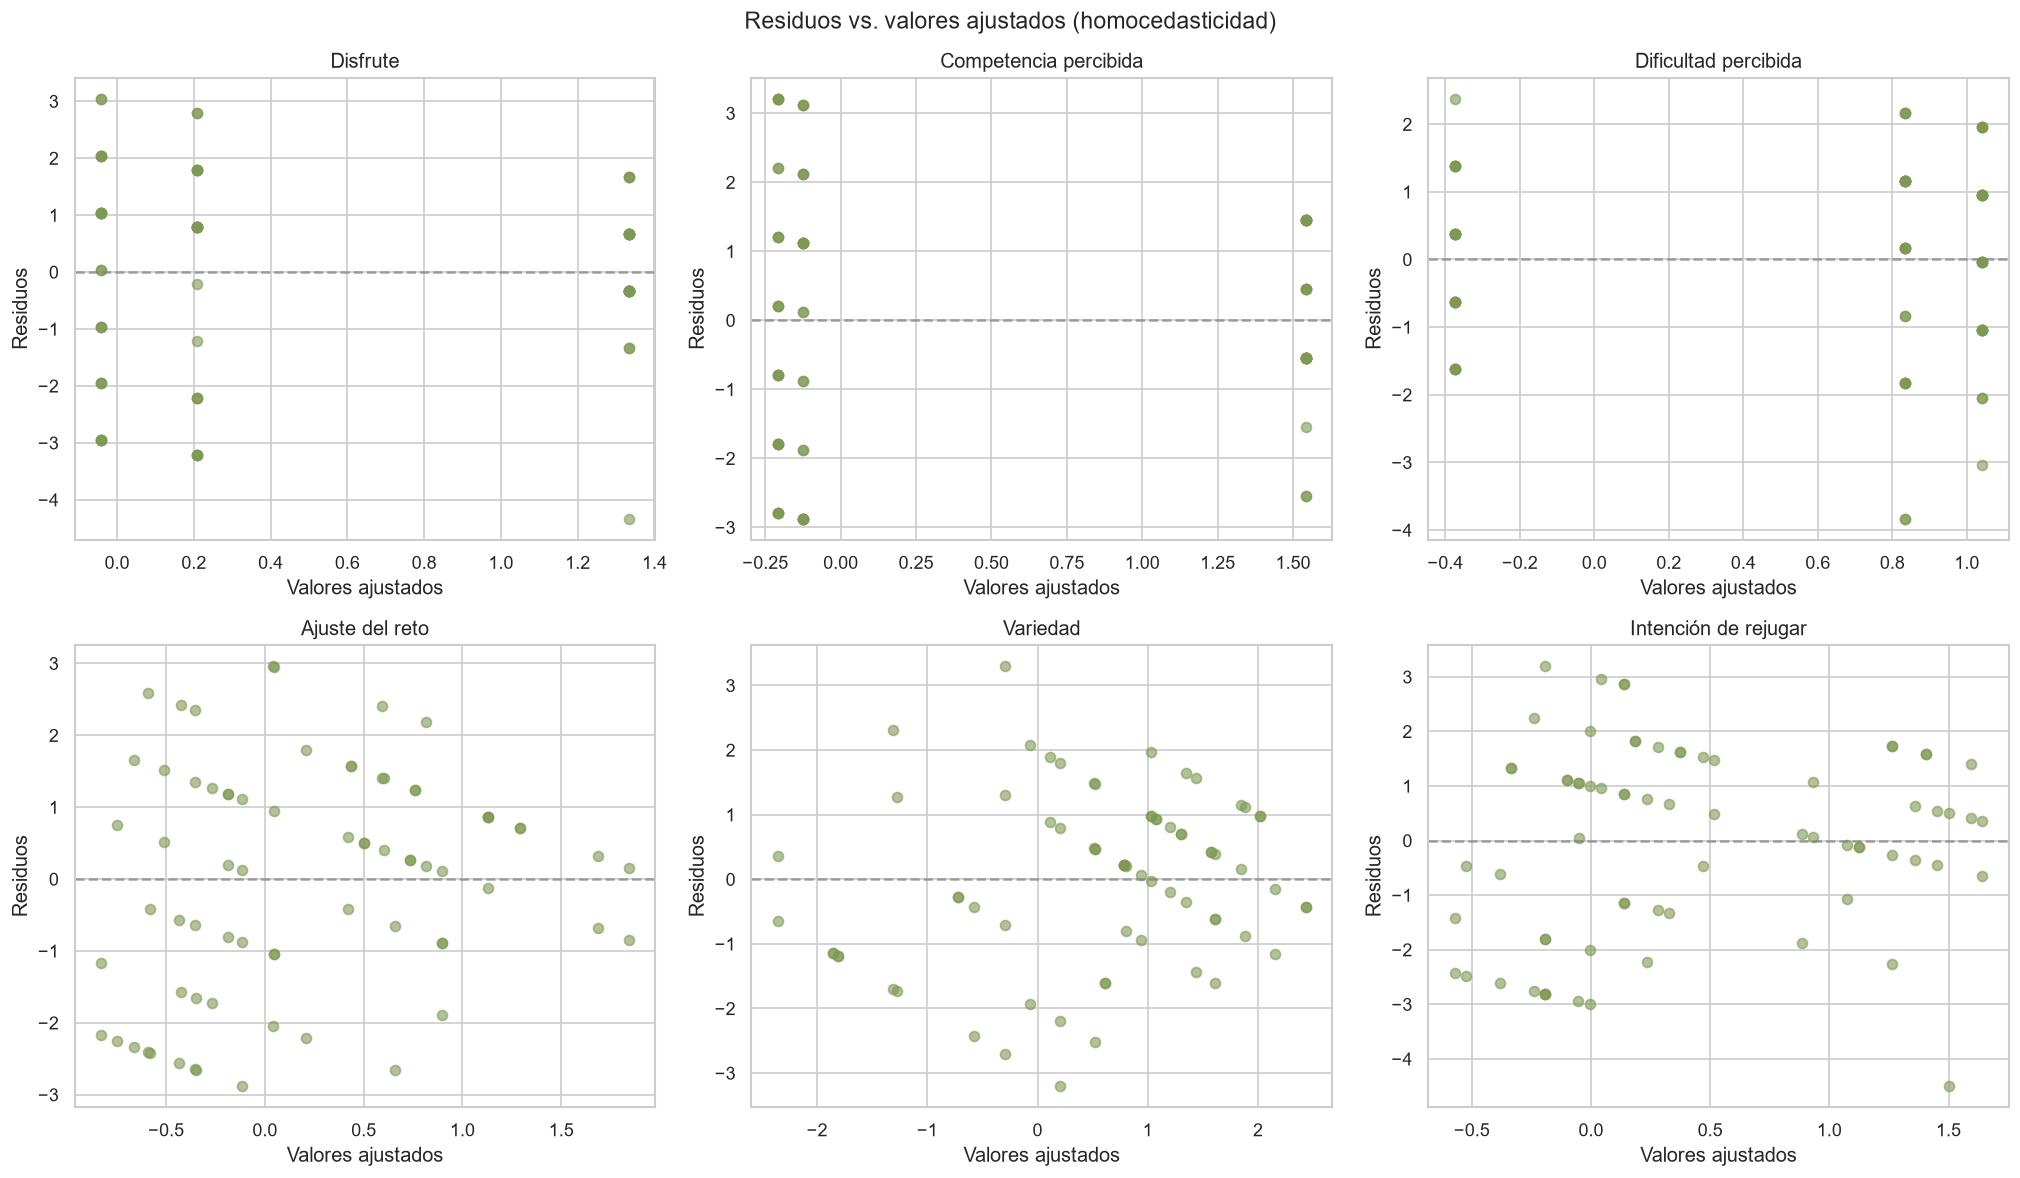

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    resultado = modelos_lmm[variable]

    ax.scatter(resultado.fittedvalues, resultado.resid, alpha=0.6, color="#7e9953")
    ax.axhline(0, color="gray", linestyle="--", alpha=0.7)
    ax.set_xlabel("Valores ajustados")
    ax.set_ylabel("Residuos")
    ax.set_title(nombres_variables[variable])

fig.suptitle("Residuos vs. valores ajustados (homocedasticidad)", fontsize=14)
fig.tight_layout()
plt.show()

### Etapa 5: Comparaciones por pares

El modelo `dv ~ condicion` ya es, en sí mismo, una prueba ómnibus con 3
niveles (como el ANOVA): los dos coeficientes (`LLM sin telemetría` y
`LLM con telemetría`, ambos contra `Humano`) nos dan directamente 2 de las
3 comparaciones posibles. La comparación que falta,
**LLM sin telemetría vs. LLM con telemetría**, se obtiene con una prueba de
contraste lineal (`t_test`) sobre la diferencia de esos dos coeficientes.

Como para cada variable estamos haciendo **3 comparaciones** (una familia
de pruebas relacionadas), corregimos los p-valores dentro de cada variable
con el método de **Holm-Bonferroni** (`multipletests`, más potente que un
Bonferroni simple y igual de válido para controlar el error tipo I).

In [19]:
from statsmodels.stats.multitest import multipletests

filas_comparaciones = []

for variable in variables:

    resultado = modelos_lmm[variable]

    coef_n = resultado.params["condicion[T.LLM sin telemetría]"]
    coef_p = resultado.params["condicion[T.LLM con telemetría]"]
    p_h_vs_n = resultado.pvalues["condicion[T.LLM sin telemetría]"]
    p_h_vs_p = resultado.pvalues["condicion[T.LLM con telemetría]"]

    contraste_n_vs_p = resultado.t_test(np.array([[0, -1, 1]]))
    diff_n_vs_p = float(contraste_n_vs_p.effect[0])
    p_n_vs_p = float(contraste_n_vs_p.pvalue)

    comparaciones_variable = [
        ("Humano vs. LLM sin telemetría", -coef_n, p_h_vs_n),
        ("Humano vs. LLM con telemetría", -coef_p, p_h_vs_p),
        ("LLM sin telemetría vs. LLM con telemetría", diff_n_vs_p, p_n_vs_p),
    ]

    p_valores = [c[2] for c in comparaciones_variable]
    _, p_ajustados, _, _ = multipletests(p_valores, method="holm")

    for (comparacion, diferencia, p_valor), p_ajustado in zip(comparaciones_variable, p_ajustados):
        filas_comparaciones.append({
            "Variable": nombres_variables[variable],
            "Comparación": comparacion,
            "Diferencia": diferencia,
            "p-valor": p_valor,
            "p-valor (Holm)": p_ajustado,
            "Significativo (p < 0.05)": "Sí" if p_ajustado < 0.05 else "No",
        })

tabla_comparaciones = pd.DataFrame(filas_comparaciones).round(4)

display(tabla_comparaciones)

,Variable,Comparación,Diferencia,p-valor,p-valor (Holm),Significativo (p < 0.05)
0,Disfrute,Humano vs. LLM sin telemetría,1.1250,0.0292,0.0583,No
1,Disfrute,Humano vs. LLM con telemetría,1.3750,0.0077,0.0230,Sí
2,Disfrute,LLM sin telemetría vs. LLM con telemetría,-0.2500,0.6279,0.6279,No
3,Competencia percibida,Humano vs. LLM sin telemetría,1.6667,0.0022,0.0043,Sí
4,Competencia percibida,Humano vs. LLM con telemetría,1.7500,0.0013,0.0038,Sí
5,Competencia percibida,LLM sin telemetría vs. LLM con telemetría,-0.0833,0.8781,0.8781,No
6,Dificultad percibida,Humano vs. LLM sin telemetría,-1.4167,0.0007,0.0022,Sí
7,Dificultad percibida,Humano vs. LLM con telemetría,-1.2083,0.0040,0.0080,Sí
8,Dificultad percibida,LLM sin telemetría vs. LLM con telemetría,-0.2083,0.6197,0.6197,No
9,Ajuste del reto,Humano vs. LLM sin telemetría,1.0833,0.0228,0.0456,Sí


C:\Users\emago\AppData\Local\Temp\ipykernel_18240\2276910280.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\emago\AppData\Local\Temp\ipykernel_18240\2276910280.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\emago\AppData\Local\Temp\ipykernel_18240\2276910280.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\emago\AppData\Local\Temp\ipykernel_18240\2276910280.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `h

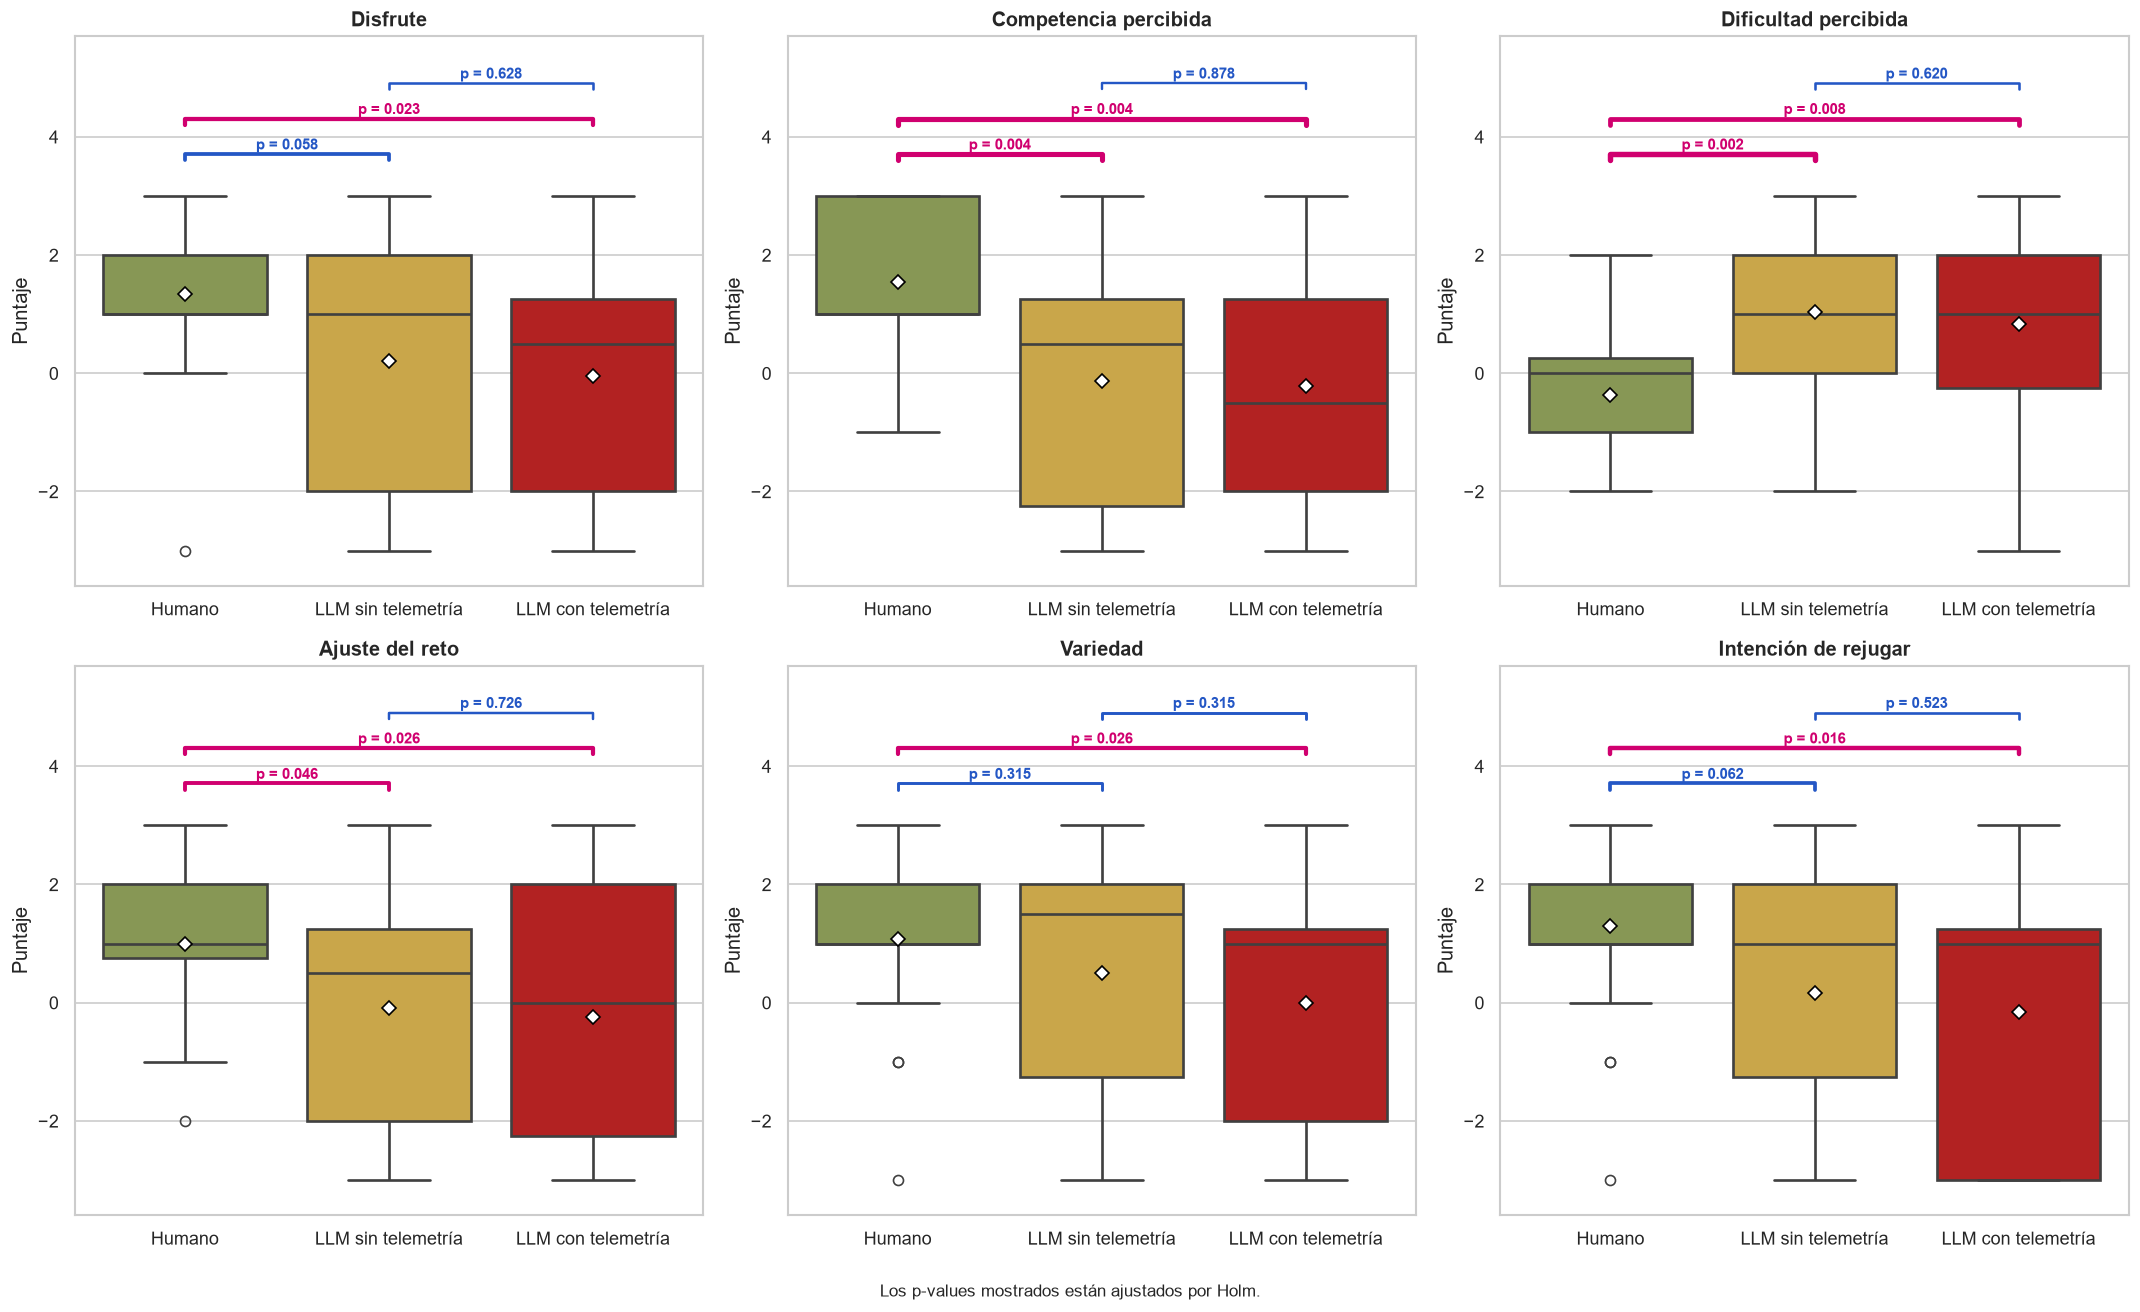

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

orden_condiciones = [
    "Humano",
    "LLM sin telemetría",
    "LLM con telemetría",
]

comparaciones_grafico = [
    ("Humano vs. LLM sin telemetría", 0, 1),
    ("Humano vs. LLM con telemetría", 0, 2),
    ("LLM sin telemetría vs. LLM con telemetría", 1, 2),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

for ax, variable in zip(axes, variables):
    nombre_variable = nombres_variables[variable]
    datos = df.dropna(subset=[variable, "condicion"])

    sns.boxplot(
        data=datos,
        x="condicion",
        y=variable,
        order=orden_condiciones,
        palette=["#879755", "#C9A64A", "#B22222"],
        saturation=1,
        linewidth=1.6,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
        },
        ax=ax,
    )

    ax.set_title(nombre_variable, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Puntaje")

    filas_variable = tabla_comparaciones[
        tabla_comparaciones["Variable"] == nombre_variable
    ]

    minimo = datos[variable].min()
    maximo = datos[variable].max()
    espacio = max(maximo - minimo, 1) * 0.10
    alto_barra = espacio * 0.18

    for nivel, (nombre_comparacion, x1, x2) in enumerate(
        comparaciones_grafico, start=1
    ):
        fila = filas_variable[
            filas_variable["Comparación"] == nombre_comparacion
        ]

        if len(fila) != 1:
            raise ValueError(
                f"Se esperaba exactamente un resultado para "
                f"{nombre_variable}: {nombre_comparacion}"
            )

        p_ajustado = float(fila.iloc[0]["p-valor (Holm)"])
        etiqueta = (
            "p < 0.001"
            if p_ajustado < 0.001
            else f"p = {p_ajustado:.3f}"
        )

        y = maximo + espacio * nivel
        p_seguro = max(p_ajustado, 1e-6)
        grosor = min(
            4.2,
            max(1.4, 1.4 + 0.7 * (-np.log10(p_seguro))),
        )
        color = "#D0006F" if p_ajustado < 0.05 else "#2457C5"

        ax.plot(
            [x1, x1, x2, x2],
            [y, y + alto_barra, y + alto_barra, y],
            color=color,
            linewidth=grosor,
            clip_on=False,
        )

        ax.text(
            (x1 + x2) / 2,
            y + alto_barra + espacio * 0.04,
            etiqueta,
            ha="center",
            va="bottom",
            color=color,
            fontweight="bold",
            fontsize=9,
        )

    ax.set_ylim(minimo - espacio, maximo + espacio * 4.5)

for ax in axes[len(variables):]:
    ax.set_visible(False)

fig.text(
    0.5,
    0.01,
    "Los p-values mostrados están ajustados por Holm.",
    ha="center",
    fontsize=10,
)

plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("boxplots_lmm_pvalues_holm.png", dpi=300, bbox_inches="tight")
plt.show()

### Etapa 6: Conclusiones

#### 1. Patrón general: Humano > LLM sin telemetría > LLM con telemetría

En **Disfrute, Competencia percibida, Ajuste del reto, Variedad e Intención
de rejugar**, las medias siguen consistentemente el orden
**Humano > LLM sin telemetría > LLM con telemetría**. Los niveles creados
por personas son los mejor evaluados, los generados por el LLM sin acceso
a telemetría quedan en un punto intermedio, y los generados con telemetría
son los peor evaluados de los tres — aunque la distancia entre estas dos
últimas variantes es pequeña y, como se vio en la Etapa 5, **nunca resultó
estadísticamente significativa** tras la corrección por comparaciones
múltiples.

La excepción aparente es **Dificultad percibida**, donde el orden de las
medias se invierte (Humano < LLM con telemetría < LLM sin telemetría). Esto
no contradice el patrón: en esta variable, un valor más alto significa
"más difícil", no "mejor experiencia". Interpretado así, el patrón es el
mismo: los niveles humanos se perciben como más accesibles, mientras que
ambas variantes de LLM se perciben como más retadoras, con una diferencia
mínima entre sí.

#### 2. ¿Qué nos dice la significancia estadística?

- **Humano vs. LLM**: diferencia significativa (p < 0.05, corregido) en
  9 de las 12 comparaciones posibles (2 variantes de LLM × 6 variables).
  Jugar un nivel humano se percibe de forma consistentemente distinta a
  jugar un nivel generado por LLM.
- **LLM sin telemetría vs. LLM con telemetría**: ninguna diferencia
  significativa en ninguna de las 6 variables. Con los datos actuales, no
  hay evidencia de que la telemetría cambie la experiencia percibida.

Es importante no interpretar este último punto como "la telemetría no
aporta nada": con solo **12 participantes** (n=72 observaciones), el
estudio tiene poder estadístico limitado para detectar diferencias
pequeñas. Es decir, **no pudimos confirmar** que haya diferencia entre N y
P con esta muestra, lo cual no es lo mismo que demostrar que no la hay.

#### 3. Limitación metodológica importante: el tiempo de juego del piloto

Esta prueba piloto se corrió con **1 minuto por nivel**, un tiempo que el
propio diseño del experimento consideraba insuficiente (la intención
original era usar 2 minutos; el cambio a 1 minuto fue un error de
configuración detectado después de que 4 personas ya habían jugado así, por
lo que se mantuvo para toda la muestra piloto por consistencia).

Este detalle es clave para interpretar los resultados de **Dificultad** y
**Disfrute** en conjunto. Los niveles personalizados (LLM) se perciben como
más difíciles que los humanos; si además el tiempo disponible para
completarlos era corto, es plausible que parte del menor Disfrute/menor
Ajuste del reto/menor Intención de rejugar observado en las condiciones LLM
no refleje únicamente que los niveles sean "menos divertidos" en sí mismos,
sino que **la combinación de mayor dificultad + poco tiempo** haya
generado frustración en vez de disfrute. Un nivel más retador puede ser muy
disfrutable si hay tiempo suficiente para explorarlo y superarlo, pero
percibirse como frustrante si el tiempo se agota antes de lograrlo.

En otras palabras: **la variable "condición" (Humano/N/P) y la variable
"dificultad real del nivel" están confundidas con el tiempo límite** en
este piloto, lo que limita cuánto podemos atribuir las diferencias de
Disfrute exclusivamente a quién diseñó el nivel.

#### 4. Lo que proponemos para el experimento definitivo

- Ejecutar el experimento real con **el doble de tiempo por nivel (2
  minutos)**, tal como se planeó originalmente, para separar el efecto de
  "quién/qué generó el nivel" del efecto de "cuánto tiempo hubo para
  disfrutarlo/superarlo".
- Aumentar el tamaño de muestra más allá de 12 participantes, para tener
  poder estadístico suficiente y poder concluir con más confianza si existe
  o no una diferencia real entre LLM sin telemetría y LLM con telemetría.
- Mantener el diseño de medidas repetidas (cada participante evalúa las 3
  condiciones) y el LMM con intercepto aleatorio por participante, que en
  este piloto demostró ser una herramienta adecuada y robusta (residuos
  razonablemente normales y homocedásticos en las 6 variables).